In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
llm_df = pd.read_csv('llm_hallucination_dataset_v1.csv')

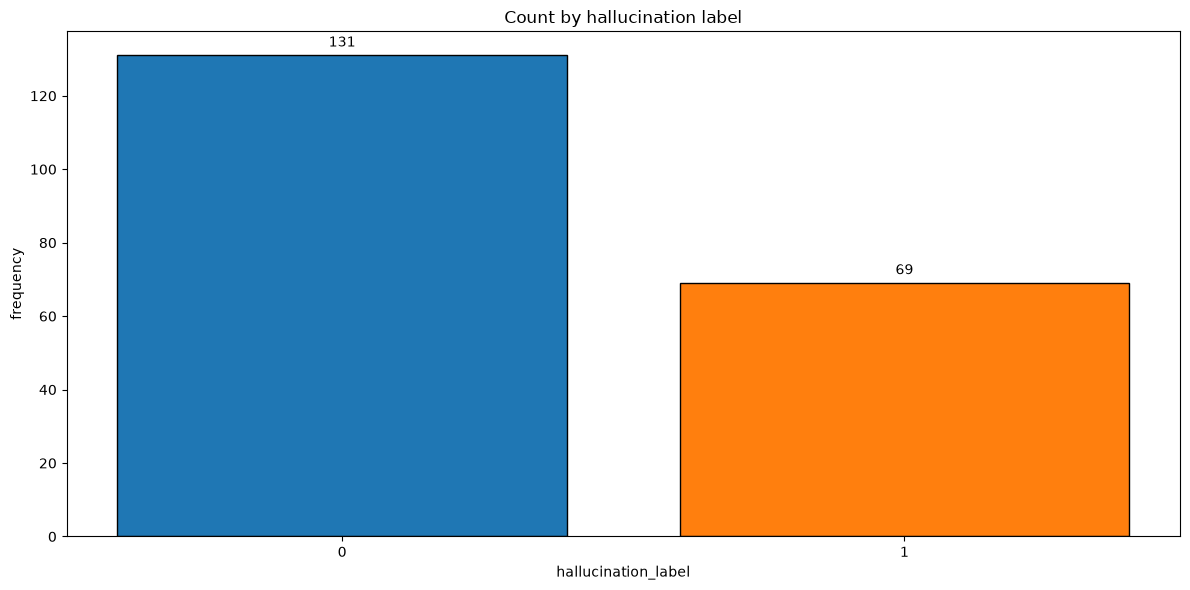

In [56]:
counts = (
    llm_df['hallucination_label']
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 6))
bars = []
for x, val in enumerate(counts.values):
    container = ax.bar(x, val, edgecolor='black')
    bars.append(container[0])

ax.set_xlabel('hallucination_label')
ax.set_ylabel('frequency')
ax.set_title('Count by hallucination label')
ax.set_xticks([0, 1])
ax.set_xticklabels(['0', '1'])

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{int(height)}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
    )

plt.tight_layout()
plt.show()

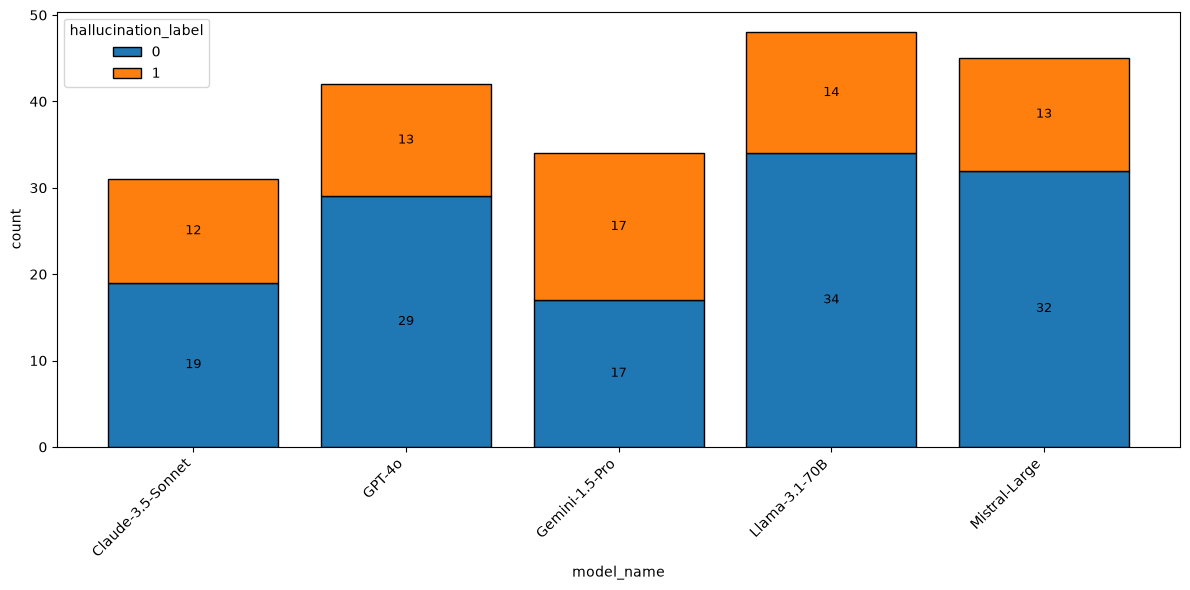

In [ ]:
counts = pd.crosstab(llm_df['model_name'], llm_df['hallucination_label'])
counts = counts.reindex(columns=[0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(counts.index))
width = 0.8
bottom = np.zeros(len(counts))

for col in [0, 1]:
    values = counts[col].to_numpy()
    bars = ax.bar(
        x,
        values,
        width,
        bottom=bottom,
        label=col,
        edgecolor='black',
    )
    for i, (bar, val) in enumerate(zip(bars, values)):
        if val > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bottom[i] + val / 2,
                str(int(val)),
                ha='center',
                va='center',
                fontsize=9,
            )
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(counts.index, rotation=45, ha='right')
ax.set_xlabel('model_name')
ax.set_ylabel('count')
ax.legend(title='hallucination_label')
plt.tight_layout()
plt.show()

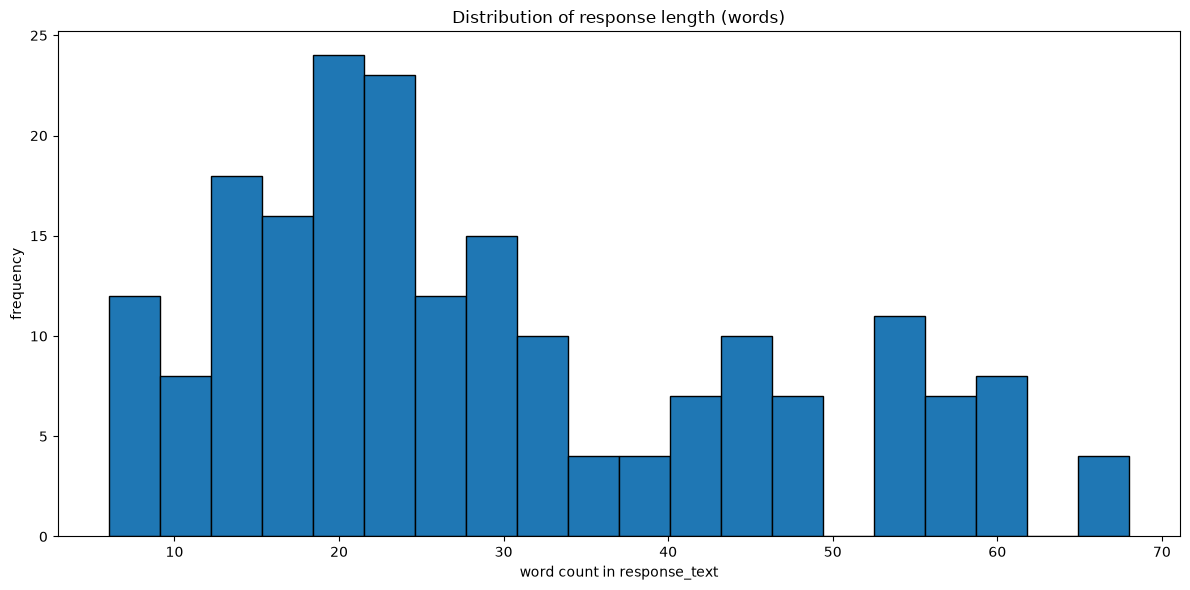

In [55]:
# word count per row (whitespace-separated tokens)
word_counts = llm_df['response_text'].astype(str).str.split().str.len()

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(word_counts, bins=20, edgecolor='black')
ax.set_xlabel('word count in response_text')
ax.set_ylabel('frequency')
ax.set_title('Distribution of response length (words)')
plt.tight_layout()
plt.show()

In [ ]:
# counts = pd.crosstab(llm_df['hallucination_label'], llm_df['model_name'])
# counts = counts.reindex(index=[0, 1], fill_value=0)

# n_models = counts.shape[1]
# colors = plt.cm.viridis(np.linspace(0.15, 0.85, n_models))  # skip ends for readability

# ax = counts.plot(
#     kind='bar',
#     stacked=True,
#     figsize=(10, 6),
#     rot=0,
#     color=colors,
# )
# ax.set_xlabel('hallucination_label')
# ax.set_ylabel('count')
# ax.set_title('Hallucination label counts by model')
# ax.legend(title='model_name')
# plt.tight_layout()
# plt.show()